 FITTED HEAT EQUATION PARAMETERS (FROM CSV)
Equilibrium Temperature (T0): 323.37 K (50.22 °C)
Thermal Diffusivity (alpha): 1.3377e-04 m^2/s
-------------------------------------------------------
Mode n=1 Amplitude (C_1): 37.671 K
Mode n=2 Amplitude (C_2): -14.018 K
Mode n=3 Amplitude (C_3): -16.930 K
Mode n=4 Amplitude (C_4): -13.125 K
Mode n=5 Amplitude (C_5): 4.168 K
Mode n=6 Amplitude (C_6): -13.954 K
Mode n=7 Amplitude (C_7): -9.293 K
Mode n=8 Amplitude (C_8): -17.452 K
Mode n=9 Amplitude (C_9): 5.747 K
Mode n=10 Amplitude (C_10): -21.861 K
Mode n=11 Amplitude (C_11): -0.355 K


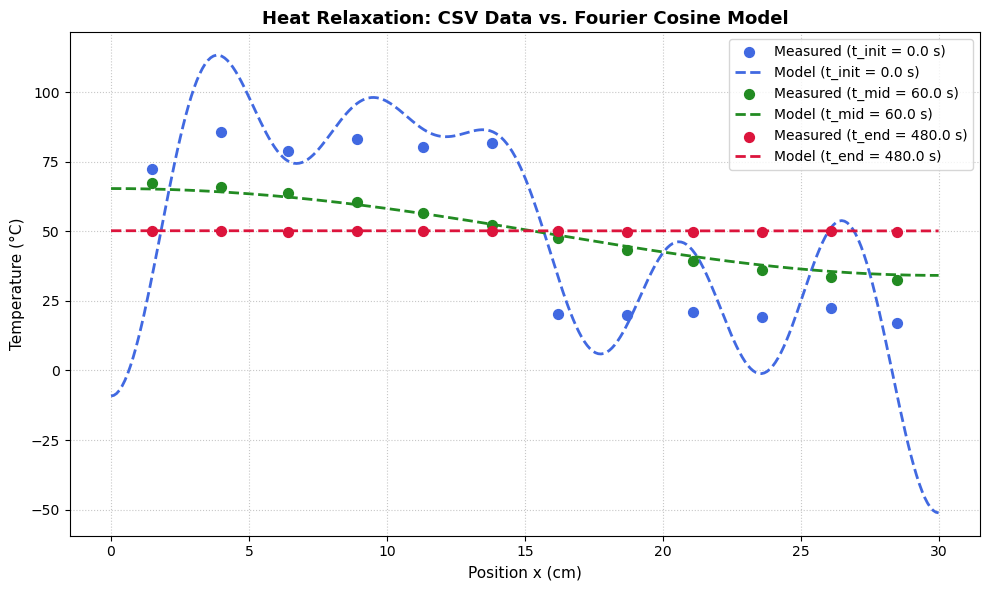

In [8]:
#This code generates the heat equation at t=0 and checks for future times

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ---------------------------------------------------------
# 1. Cosine basis coefficients calculation (from heat_equation.py)
# ---------------------------------------------------------
def get_coeffs_cos_basis(T, x, L):
    """
    Computes the cosine expansion coefficients for temperature profile T.
        coeffs[0] = mean temperature (T0)
        coeffs[n] = mode n amplitude (C_n)
    """
    N = len(x)
    coeffs = np.zeros(N)
    coeffs[0] = (1.0 / N) * np.sum(T)
    for n in range(1, N):
        coeffs[n] = (2.0 / N) * np.sum(T * np.cos(n * np.pi / L * x))
    return coeffs

# ---------------------------------------------------------
# 2. Main CSV Analysis & Model Fitting
# ---------------------------------------------------------
def analyze_heat_diffusion_csv(csv_path, M=5, is_celsius=True, L_m=0.3):
    """
    Reads CSV measurement data, estimates heat parameters, and plots profiles.
    
    Inputs:
        csv_path: Path to CSV file.
        M: Number of cosine modes to sum over.
        is_celsius: True if temperatures are in °C (converts to K), False if in Kelvin.
        L_m: Rod length in meters (default: 0.3 m = 30 cm).
    """
    # Read CSV file using pandas
    df = pd.read_csv(csv_path)
    
    # Extract x sensor positions in cm from column headers -> convert to meters
    x_sensors_cm = np.array([float(col) for col in df.columns[1:]])
    x_sensors_m = x_sensors_cm / 100.0
    N_sensors = len(x_sensors_m)
    
    # Extract times (col 0) and temperature data (cols 1..N)
    times = df.iloc[:, 0].values.astype(float)
    T_data = df.iloc[:, 1:].values.astype(float)
    
    # Temperature unit conversion to Kelvin
    if is_celsius:
        T_data_K = T_data + 273.15
    else:
        T_data_K = T_data.copy()
        
    # --- Step 1: Compute T0 and C_n from initial measurement (t = t_init) ---
    T_init = T_data_K[0, :]
    initial_coeffs = get_coeffs_cos_basis(T_init, x_sensors_m, L_m)
    
    T0_est = initial_coeffs[0]
    C_n_est = initial_coeffs[1:M+1]
    
    # --- Step 2: Fit Thermal Diffusivity (alpha) across space & time ---
    T_grid, X_grid = np.meshgrid(times, x_sensors_m, indexing='ij')
    times_flat = T_grid.flatten()
    x_flat = X_grid.flatten()
    T_measured_flat = T_data_K.flatten()
    
    def model_func(X_and_T, alpha):
        t_val, x_val = X_and_T
        T_pred = np.full_like(x_val, T0_est)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_n_est[n-1] * np.exp(-alpha * (k_n**2) * t_val)
            T_pred += b_n * np.cos(k_n * x_val)
        return T_pred

    # Fit alpha using non-linear least squares
    popt, _ = curve_fit(model_func, (times_flat, x_flat), T_measured_flat, p0=[1.0e-4], bounds=(1e-7, 1e-2))
    alpha_fit = popt[0]
    
    # Print fitted constants
    print("=" * 55)
    print(" FITTED HEAT EQUATION PARAMETERS (FROM CSV)")
    print("=" * 55)
    print(f"Equilibrium Temperature (T0): {T0_est:.2f} K ({T0_est - 273.15:.2f} °C)")
    print(f"Thermal Diffusivity (alpha): {alpha_fit:.4e} m^2/s")
    print("-" * 55)
    for n in range(1, M + 1):
        print(f"Mode n={n} Amplitude (C_{n}): {C_n_est[n-1]:.3f} K")
    print("=" * 55)
    
    # --- Step 3: Evaluate model and plot t_init, t_mid, t_end ---
    def eval_model(x_dense, t):
        T_eval = np.full_like(x_dense, T0_est)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_n_est[n-1] * np.exp(-alpha_fit * (k_n**2) * t)
            T_eval += b_n * np.cos(k_n * x_dense)
        return T_eval

    idx_init = 0
    idx_mid = len(times) // 2
    idx_end = len(times) - 1
    
    time_points = [
        (idx_init, f"t_init = {times[idx_init]:.1f} s", 'royalblue'),
        (idx_mid,  f"t_mid = {times[idx_mid]:.1f} s",   'forestgreen'),
        (idx_end,  f"t_end = {times[idx_end]:.1f} s",   'crimson')
    ]
    
    x_dense = np.linspace(0, L_m, 300)
    x_dense_cm = x_dense * 100.0
    
    plt.figure(figsize=(10, 6))
    
    for idx, label, color in time_points:
        t_val = times[idx]
        T_measured = T_data_K[idx, :]
        T_smooth = eval_model(x_dense, t_val)
        
        if is_celsius:
            T_measured_disp = T_measured - 273.15
            T_smooth_disp = T_smooth - 273.15
            y_label = "Temperature (°C)"
        else:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth
            y_label = "Temperature (K)"
            
        plt.scatter(x_sensors_cm, T_measured_disp, color=color, s=50, zorder=5, label=f"Measured ({label})")
        plt.plot(x_dense_cm, T_smooth_disp, color=color, linewidth=2, linestyle='--', label=f"Model ({label})")
        
    plt.title("Heat Relaxation: CSV Data vs. Fourier Cosine Model", fontsize=13, fontweight='bold')
    plt.xlabel("Position x (cm)", fontsize=11)
    plt.ylabel(y_label, fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.show()

# Run analysis on CSV file
if __name__ == "__main__":
    analyze_heat_diffusion_csv("heat_measurement_example.csv", M=11, is_celsius=True, L_m=0.3)


 GLOBAL FIT RESULTS (Sensors N = 12, Modes M = 20)
Equilibrium Temperature (T0): 323.15 K (50.00 °C)
Thermal Diffusivity (alpha): 1.1621e-04 m^2/s
------------------------------------------------------------
Mode C_01: 37.916 K
Mode C_02: -1.889 K
Mode C_03: -14.474 K
Mode C_04: -1.957 K
Mode C_05: 7.188 K
Mode C_06: -2.098 K
Mode C_07: -7.494 K
Mode C_08: -2.126 K
Mode C_09: 2.123 K
Mode C_10: -3.054 K
Mode C_11: -4.959 K
Mode C_12: -1.472 K
Mode C_13: 1.248 K
Mode C_14: -0.149 K
Mode C_15: -2.291 K
Mode C_16: 0.406 K
Mode C_17: 0.640 K
Mode C_18: 0.086 K
Mode C_19: -0.003 K
Mode C_20: 0.082 K


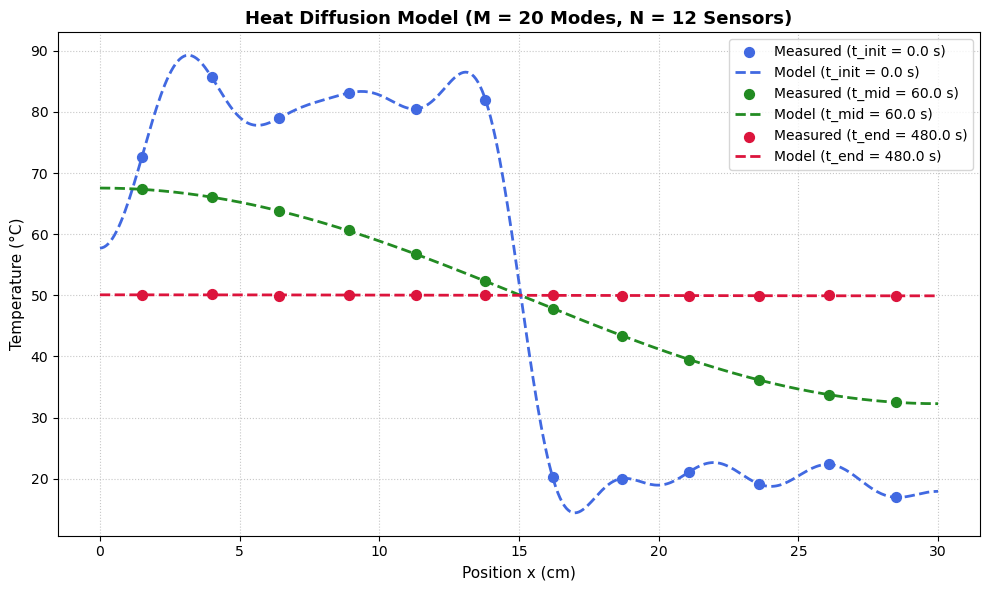

In [10]:
#This code fits the whole time spectrum of the measurement
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def analyze_heat_diffusion_arbitrary_M(csv_path, M=16, is_celsius=True, L_m=0.3):
    """
    Fits heat diffusion parameters T0, C_1..C_M, and alpha simultaneously.
    Allows M > N by performing global spatiotemporal optimization across all (x_i, t_j).
    
    Inputs:
        csv_path: Path to CSV data file.
        M: Number of cosine modes (can be greater than N).
        is_celsius: True if input temps are in °C (converts to K), False if in Kelvin.
        L_m: Rod length in meters (default: 0.3 m = 30 cm).
    """
    # 1. Load CSV data
    df = pd.read_csv(csv_path)
    
    # Sensor positions in cm -> convert to meters
    x_sensors_cm = np.array([float(col) for col in df.columns[1:]])
    x_sensors_m = x_sensors_cm / 100.0
    N_sensors = len(x_sensors_m)
    
    # Times and temperatures
    times = df.iloc[:, 0].values.astype(float)
    T_data = df.iloc[:, 1:].values.astype(float)
    
    # Temperature conversion to Kelvin
    if is_celsius:
        T_data_K = T_data + 273.15
    else:
        T_data_K = T_data.copy()
        
    # 2. Flatten space-time grid for global multi-variable optimization
    T_grid, X_grid = np.meshgrid(times, x_sensors_m, indexing='ij')
    times_flat = T_grid.flatten()
    x_flat = X_grid.flatten()
    T_measured_flat = T_data_K.flatten()
    
    # 3. Define multi-parameter target model
    def heat_model_global(X_and_T, T0, *params):
        # params: [C_1, C_2, ..., C_M, alpha]
        C_vec = params[:M]
        alpha = params[M]
        
        t_val, x_val = X_and_T
        T_pred = np.full_like(x_val, T0)
        
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            T_pred += C_vec[n-1] * np.exp(-alpha * (k_n**2) * t_val) * np.cos(k_n * x_val)
        return T_pred

    # Initial guesses & physical bounds
    # Parameter order in curve_fit: [T0, C_1, ..., C_M, alpha]
    p0 = [np.mean(T_data_K)] + [0.0] * M + [1.0e-4]
    bounds_lower = [0.0] + [-np.inf] * M + [1.0e-8]
    bounds_upper = [np.inf] + [np.inf] * M + [1.0e-2]
    
    # Perform global optimization
    popt, _ = curve_fit(
        heat_model_global, 
        (times_flat, x_flat), 
        T_measured_flat, 
        p0=p0, 
        bounds=(bounds_lower, bounds_upper)
    )
    
    # Unpack fitted parameters
    T0_fit = popt[0]
    C_fit = popt[1:M+1]
    alpha_fit = popt[M+1]
    
    # Print summary
    print("=" * 60)
    print(f" GLOBAL FIT RESULTS (Sensors N = {N_sensors}, Modes M = {M})")
    print("=" * 60)
    print(f"Equilibrium Temperature (T0): {T0_fit:.2f} K ({T0_fit - 273.15:.2f} °C)")
    print(f"Thermal Diffusivity (alpha): {alpha_fit:.4e} m^2/s")
    print("-" * 60)
    for n in range(1, M + 1):
        print(f"Mode C_{n:02d}: {C_fit[n-1]:.3f} K")
    print("=" * 60)
    
    # 4. Dense evaluation for continuous spatial curves
    def eval_model(x_dense, t):
        T_eval = np.full_like(x_dense, T0_fit)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_fit[n-1] * np.exp(-alpha_fit * (k_n**2) * t)
            T_eval += b_n * np.cos(k_n * x_dense)
        return T_eval

    idx_init = 0
    idx_mid = len(times) // 2
    idx_end = len(times) - 1
    
    time_points = [
        (idx_init, f"t_init = {times[idx_init]:.1f} s", 'royalblue'),
        (idx_mid,  f"t_mid = {times[idx_mid]:.1f} s",   'forestgreen'),
        (idx_end,  f"t_end = {times[idx_end]:.1f} s",   'crimson')
    ]
    
    x_dense = np.linspace(0, L_m, 400)
    x_dense_cm = x_dense * 100.0
    
    # Plotting
    plt.figure(figsize=(10, 6))
    for idx, label, color in time_points:
        t_val = times[idx]
        T_measured = T_data_K[idx, :]
        T_smooth = eval_model(x_dense, t_val)
        
        if is_celsius:
            T_measured_disp = T_measured - 273.15
            T_smooth_disp = T_smooth - 273.15
            y_label = "Temperature (°C)"
        else:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth
            y_label = "Temperature (K)"
            
        plt.scatter(x_sensors_cm, T_measured_disp, color=color, s=50, zorder=5, label=f"Measured ({label})")
        plt.plot(x_dense_cm, T_smooth_disp, color=color, linewidth=2, linestyle='--', label=f"Model ({label})")
        
    plt.title(f"Heat Diffusion Model (M = {M} Modes, N = {N_sensors} Sensors)", fontsize=13, fontweight='bold')
    plt.xlabel("Position x (cm)", fontsize=11)
    plt.ylabel(y_label, fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.show()

# Run with M = 16 modes on N = 12 sensors dataset
if __name__ == "__main__":
    analyze_heat_diffusion_arbitrary_M("heat_measurement_example.csv", M=20, is_celsius=True, L_m=0.3)


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import t

def analyze_heat_diffusion_complete(
    csv_path, 
    M=12, 
    is_celsius=True, 
    L_m=0.3, 
    fix_T_env=False, 
    T_env_user_K=293.15
):
    """
    Fits 1D heat diffusion with convective loss:
      T(x, t) = T_env + (T0_init - T_env)*exp(-gamma*t) + sum_{n=1}^M C_n * exp(-(alpha*k_n^2 + gamma)*t) * cos(k_n * x)

    Inputs:
        csv_path     : Path to CSV data file.
        M            : Number of spatial Fourier modes.
        is_celsius   : True if input measurements are in °C, False if in Kelvin.
        L_m          : Rod length in meters (default: 0.3 m = 30 cm).
        fix_T_env    : True to manually fix ambient temperature, False to let curve_fit find it.
        T_env_user_K : Ambient temperature in Kelvin (used when fix_T_env=True).
    """
    # 1. Read CSV File
    df = pd.read_csv(csv_path)
    
    # Sensor positions in cm -> convert to meters
    x_sensors_cm = np.array([float(col) for col in df.columns[1:]])
    x_sensors_m = x_sensors_cm / 100.0
    N_sensors = len(x_sensors_m)
    
    # Times and temperature data
    times = df.iloc[:, 0].values.astype(float)
    T_data_orig = df.iloc[:, 1:].values.astype(float)
    T_data_K = (T_data_orig + 273.15) if is_celsius else T_data_orig.copy()
        
    # Flatten space-time grid for global multi-variable optimization
    T_grid, X_grid = np.meshgrid(times, x_sensors_m, indexing='ij')
    times_flat = T_grid.flatten()
    x_flat = X_grid.flatten()
    T_measured_flat = T_data_K.flatten()
    N_data = len(T_measured_flat)
    
    # 2. Fit Parameters & Extract Covariance Matrix (pcov)
    if fix_T_env:
        # Fixed Environment Temperature Model
        def heat_model_fixed(X_and_T, T0_init, alpha, gamma, *C_params):
            t_val, x_val = X_and_T
            T_pred = T_env_user_K + (T0_init - T_env_user_K) * np.exp(-gamma * t_val)
            for n in range(1, M + 1):
                k_n = n * np.pi / L_m
                b_n = C_params[n-1] * np.exp(-(alpha * (k_n**2) + gamma) * t_val)
                T_pred += b_n * np.cos(k_n * x_val)
            return T_pred
        
        p0 = [323.15, 1.0e-4, 0.002] + [0.0] * M
        bounds_lower = [290.0, 1.0e-8, 0.0] + [-np.inf] * M
        bounds_upper = [360.0, 1.0e-2, 0.1] + [np.inf] * M
        
        popt, pcov = curve_fit(
            heat_model_fixed, 
            (times_flat, x_flat), 
            T_measured_flat, 
            p0=p0, 
            bounds=(bounds_lower, bounds_upper)
        )
        
        T_env_fit = T_env_user_K
        T0_init_fit, alpha_fit, gamma_fit = popt[:3]
        C_fit = popt[3:]
        idx_alpha, idx_gamma = 1, 2

    else:
        # Free Environment Temperature Model (curve_fit optimizes T_env)
        def heat_model_free(X_and_T, T_env, T0_init, alpha, gamma, *C_params):
            t_val, x_val = X_and_T
            T_pred = T_env + (T0_init - T_env) * np.exp(-gamma * t_val)
            for n in range(1, M + 1):
                k_n = n * np.pi / L_m
                b_n = C_params[n-1] * np.exp(-(alpha * (k_n**2) + gamma) * t_val)
                T_pred += b_n * np.cos(k_n * x_val)
            return T_pred
        
        p0 = [293.15, 323.15, 1.0e-4, 0.002] + [0.0] * M
        bounds_lower = [270.0, 290.0, 1.0e-8, 0.0] + [-np.inf] * M
        bounds_upper = [310.0, 360.0, 1.0e-2, 0.1] + [np.inf] * M
        
        popt, pcov = curve_fit(
            heat_model_free, 
            (times_flat, x_flat), 
            T_measured_flat, 
            p0=p0, 
            bounds=(bounds_lower, bounds_upper)
        )
        
        T_env_fit, T0_init_fit, alpha_fit, gamma_fit = popt[:4]
        C_fit = popt[4:]
        idx_alpha, idx_gamma = 2, 3

    # 3. Compute Standard Errors & 95% Confidence Intervals
    perr = np.sqrt(np.diag(pcov))  # 1-sigma standard errors
    N_params = len(popt)
    dof = max(1, N_data - N_params)
    t_val_crit = t.ppf(0.975, dof)  # Two-tailed Student's t critical value

    err_alpha = perr[idx_alpha]
    err_gamma = perr[idx_gamma]
    ci95_alpha = t_val_crit * err_alpha
    ci95_gamma = t_val_crit * err_gamma

    # Print Summary Report
    env_status = f"Fixed ({T_env_fit:.2f} K)" if fix_T_env else f"Fitted ({T_env_fit:.2f} K)"
    print("=" * 70)
    print(f" HEAT EQUATION FIT RESULTS & UNCERTAINTIES (Env: {env_status})")
    print("=" * 70)
    print(f"Thermal Diffusivity (alpha):")
    print(f"  Value       : {alpha_fit:.4e} m^2/s")
    print(f"  1-sigma Err : +/- {err_alpha:.4e} m^2/s ({err_alpha/alpha_fit*100:.2f}%)")
    print(f"  95% CI      : [{alpha_fit - ci95_alpha:.4e}, {alpha_fit + ci95_alpha:.4e}] m^2/s")
    print("-" * 70)
    print(f"Cooling Loss Rate (gamma):")
    print(f"  Value       : {gamma_fit:.4e} 1/s")
    print(f"  1-sigma Err : +/- {err_gamma:.4e} 1/s ({err_gamma/gamma_fit*100:.2f}%)")
    print(f"  95% CI      : [{gamma_fit - ci95_gamma:.4e}, {gamma_fit + ci95_gamma:.4e}] 1/s")
    print("-" * 70)
    print(f"Mean Initial Temp (T0_init): {T0_init_fit - 273.15:.2f} °C")
    if not fix_T_env:
        print(f"Ambient Temp (T_env)       : {T_env_fit - 273.15:.2f} +/- {perr[0]:.2f} °C")
    print("=" * 70)

    # 4. Dense Grid Evaluation & Graph Generation (t_init, t_mid, t_end)
    x_dense = np.linspace(0, L_m, 400)
    x_dense_cm = x_dense * 100.0

    def eval_model(x_dense, t):
        T_eval = T_env_fit + (T0_init_fit - T_env_fit) * np.exp(-gamma_fit * t)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_fit[n-1] * np.exp(-(alpha_fit * (k_n**2) + gamma_fit) * t)
            T_eval += b_n * np.cos(k_n * x_dense)
        return T_eval

    idx_init = 0
    idx_mid = len(times) // 2
    idx_end = len(times) - 1

    time_points = [
        (idx_init, f"t_init = {times[idx_init]:.0f} s", 'royalblue'),
        (idx_mid,  f"t_mid = {times[idx_mid]:.0f} s",   'forestgreen'),
        (idx_end,  f"t_end = {times[idx_end]:.0f} s",   'crimson')
    ]

    plt.figure(figsize=(10, 6))
    for idx, label, color in time_points:
        t_val = times[idx]
        T_measured = T_data_orig[idx, :]
        T_smooth = eval_model(x_dense, t_val)
        
        if is_celsius:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth - 273.15
            y_label = "Temperature (°C)"
        else:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth
            y_label = "Temperature (K)"
            
        plt.scatter(x_sensors_cm, T_measured_disp, color=color, s=50, zorder=5, label=f"Measured ({label})")
        plt.plot(x_dense_cm, T_smooth_disp, color=color, linewidth=2, linestyle='--', label=f"Model ({label})")

    title_str = (
        f"Heat Diffusion with System Loss & Uncertainty Estimation\n"
        f"alpha = ({alpha_fit:.3e} +/- {err_alpha:.3e}) m^2/s,  gamma = ({gamma_fit:.3e} +/- {err_gamma:.3e}) s^-1"
    )
    plt.title(title_str, fontsize=11, fontweight='bold')
    plt.xlabel("Position x (cm)", fontsize=11)
    plt.ylabel(y_label, fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.show()

 HEAT EQUATION FIT RESULTS & UNCERTAINTIES (Env: Fitted (293.16 K))
Thermal Diffusivity (alpha):
  Value       : 1.1612e-04 m^2/s
  1-sigma Err : +/- 1.3170e-07 m^2/s (0.11%)
  95% CI      : [1.1586e-04, 1.1638e-04] m^2/s
----------------------------------------------------------------------
Cooling Loss Rate (gamma):
  Value       : 2.5008e-03 1/s
  1-sigma Err : +/- 7.1400e-06 1/s (0.29%)
  95% CI      : [2.4868e-03, 2.5149e-03] 1/s
----------------------------------------------------------------------
Mean Initial Temp (T0_init): 50.00 °C
Ambient Temp (T_env)       : 20.01 +/- 0.05 °C


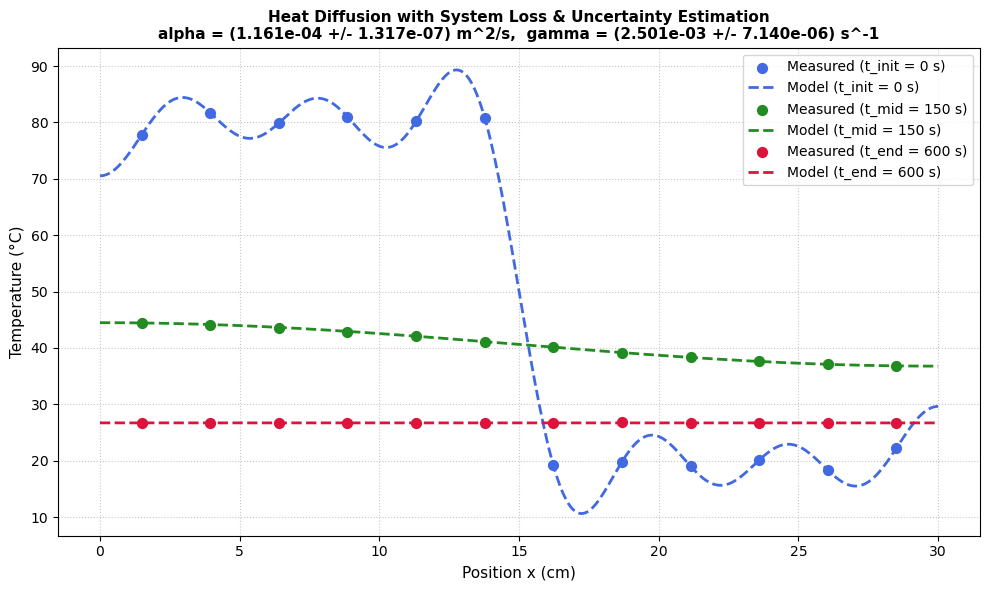

In [5]:
#Analyzing loss without given temperature of environment

analyze_heat_diffusion_complete(
        "heat_measurement_with_loss.csv", 
        M=12, 
        is_celsius=True, 
        L_m=0.3, 
        fix_T_env=False)

 HEAT EQUATION FIT RESULTS & UNCERTAINTIES (Env: Fixed (293.15 K))
Thermal Diffusivity (alpha):
  Value       : 1.1613e-04 m^2/s
  1-sigma Err : +/- 1.1754e-07 m^2/s (0.10%)
  95% CI      : [1.1590e-04, 1.1636e-04] m^2/s
----------------------------------------------------------------------
Cooling Loss Rate (gamma):
  Value       : 2.4998e-03 1/s
  1-sigma Err : +/- 1.7204e-06 1/s (0.07%)
  95% CI      : [2.4964e-03, 2.5032e-03] 1/s
----------------------------------------------------------------------
Mean Initial Temp (T0_init): 50.00 °C


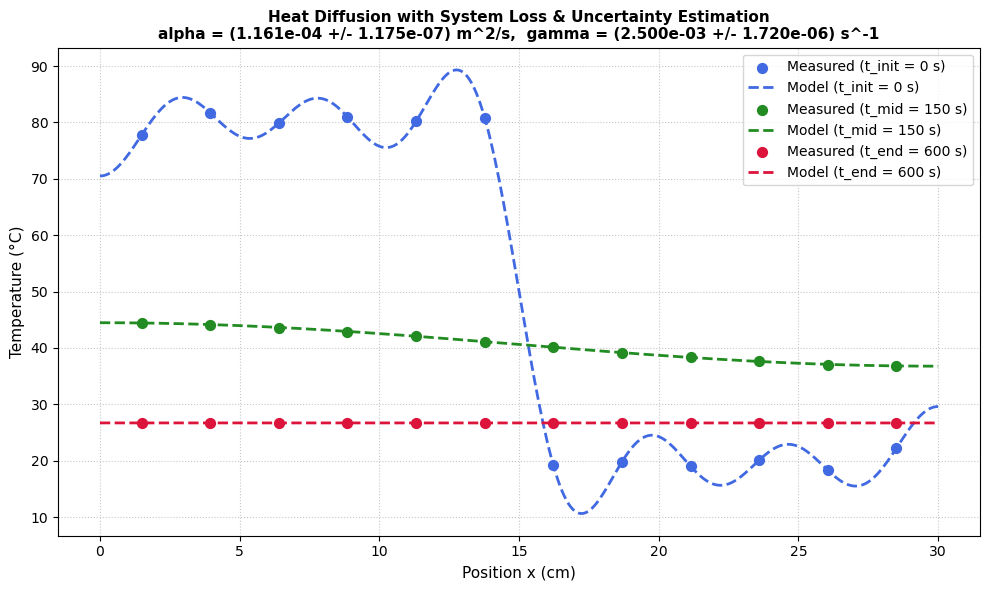

In [6]:
#analyzing loss heat equation WITH given temperature of environment

analyze_heat_diffusion_complete(
        "heat_measurement_with_loss.csv", 
        M=12, 
        is_celsius=True, 
        L_m=0.3, 
        fix_T_env=True, 
        T_env_user_K=293.15
    )

In [ ]:
|